In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Task 1: Generate the dataset
np.random.seed(42)

experience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * experience + noise

df = pd.DataFrame({
    "YearsOfExperience": experience,
    "Salary": salary
})

print(df.head())
print("Shape:", df.shape)

   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454
Shape: (500, 2)


In [3]:
# Task 2: Explore the dataset
print("Dataset shape:", df.shape)

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

correlation = df["YearsOfExperience"].corr(df["Salary"])
print("\nCorrelation:", correlation)

Dataset shape: (500, 2)

Summary statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204

Missing values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation: 0.975058457607618


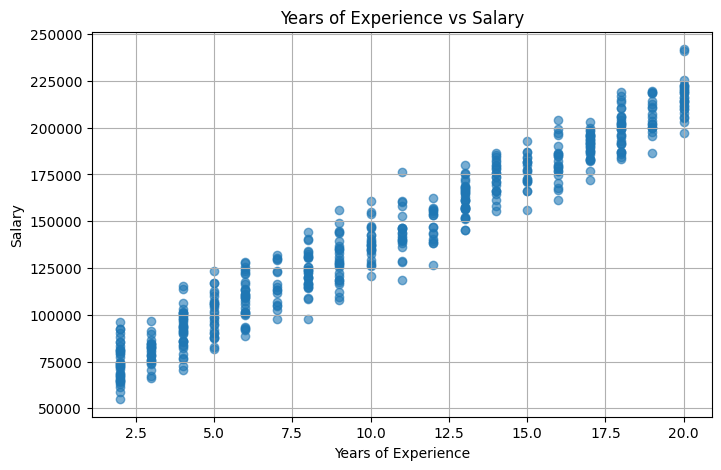

In [4]:
# Task 3: Plot the data
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.6)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")
plt.grid(True)
plt.show()

In [5]:
# Task 4: Split the dataset
X = df[["YearsOfExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 400
Test records: 100


In [6]:
# Task 5: Train linear regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)
print("Training R2:", linear_model.score(X_train, y_train))
print("Test R2:", linear_model.score(X_test, y_test))

Slope: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141


In [7]:
# Task 6: Evaluate linear regression
y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})
print("\nFirst five actual and predicted salaries:")
display(comparison.head())

MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152
R2: 0.9573704756930141

First five actual and predicted salaries:


,Actual Salary,Predicted Salary
0,123631.230350,107141.018419
1,139775.630647,122534.244265
2,93184.812446,107141.018419
3,166740.803478,161017.308880
4,174587.183981,184107.147649


In [8]:
# Task 7: Compare with a baseline
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", mae)
print("Baseline RMSE:", baseline_rmse)
print("Linear Regression RMSE:", rmse)

if mae < baseline_mae and rmse < baseline_rmse:
    print("Linear regression performs better than the mean baseline.")
else:
    print("The mean baseline performs better on at least one of these metrics.")

Baseline MAE: 40444.95787424255
Linear Regression MAE: 7905.114728709239
Baseline RMSE: 46953.769510036946
Linear Regression RMSE: 9691.918147584152
Linear regression performs better than the mean baseline.


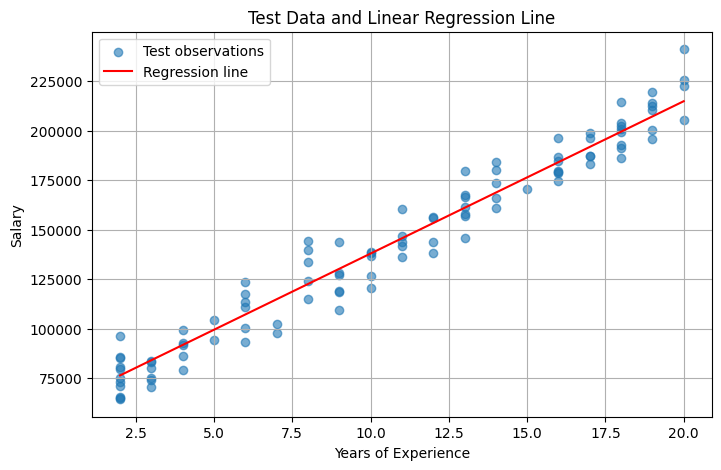

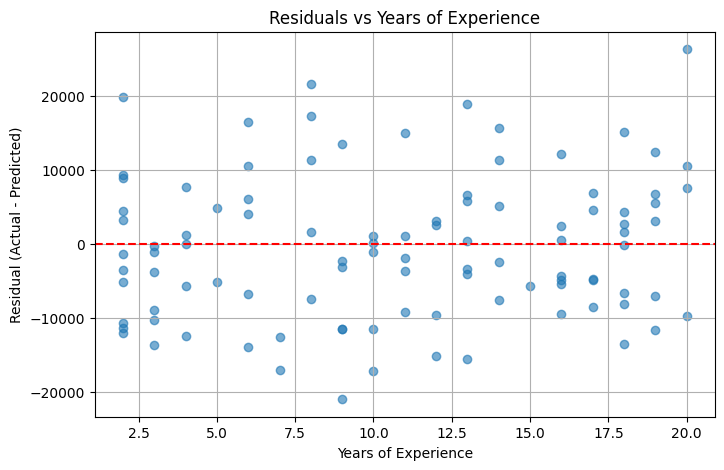

In [9]:
# Task 8: Plot predictions and residuals
# Graph (a): test observations and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], y_test, alpha=0.6, label="Test observations")

x_line = np.linspace(X_test["YearsOfExperience"].min(),
                     X_test["YearsOfExperience"].max(), 100)
y_line = linear_model.predict(pd.DataFrame({"YearsOfExperience": x_line}))
plt.plot(x_line, y_line, color="red", label="Regression line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Test Data and Linear Regression Line")
plt.legend()
plt.grid(True)
plt.show()

# Graph (b): residuals
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Years of Experience")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Years of Experience")
plt.grid(True)
plt.show()

In [10]:
# Task 9: Predict new salaries
new_experience = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15]
})
new_salary = linear_model.predict(new_experience)

new_predictions = pd.DataFrame({
    "YearsOfExperience": new_experience["YearsOfExperience"],
    "Predicted Salary": new_salary
})
display(new_predictions)

,YearsOfExperience,Predicted Salary
0,5,99444.405496
1,10,137927.470111
2,15,176410.534726


In [11]:
# Task 10: Standardize the feature
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training feature mean:", X_train_scaled.mean())
print("Scaled training feature standard deviation:", X_train_scaled.std())

Scaled training feature mean: 1.4210854715202004e-16
Scaled training feature standard deviation: 1.0


In [12]:
# Task 11: Train Ridge regression
ridge_10 = Ridge(alpha=10)
ridge_100 = Ridge(alpha=100)

ridge_10.fit(X_train_scaled, y_train)
ridge_100.fit(X_train_scaled, y_train)

ridge_results = []

for name, model in [("Ridge alpha=10", ridge_10),
                    ("Ridge alpha=100", ridge_100)]:
    predictions = model.predict(X_test_scaled)
    model_mae = mean_absolute_error(y_test, predictions)
    model_r2 = r2_score(y_test, predictions)

    ridge_results.append({
        "Model": name,
        "Coefficient": model.coef_[0],
        "Test MAE": model_mae,
        "Test R2": model_r2
    })

display(pd.DataFrame(ridge_results))
print("Compare the coefficients above: stronger regularization (larger alpha) generally shrinks the coefficient more.")

,Model,Coefficient,Test MAE,Test R2
0,Ridge alpha=10,42156.503108,8084.461348,0.955727
1,Ridge alpha=100,34568.332548,11308.369994,0.911838


Compare the coefficients above: stronger regularization (larger alpha) generally shrinks the coefficient more.


In [13]:
# Task 12: Train Lasso regression
lasso_models = {}
lasso_results = []

for alpha in [1000, 10000, 50000]:
    model = Lasso(alpha=alpha, max_iter=20000)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    model_mae = mean_absolute_error(y_test, predictions)
    model_r2 = r2_score(y_test, predictions)

    lasso_models[alpha] = model
    lasso_results.append({
        "Alpha": alpha,
        "Coefficient": model.coef_[0],
        "Test MAE": model_mae,
        "Test R2": model_r2
    })

display(pd.DataFrame(lasso_results))
print("As alpha increases, Lasso penalizes the coefficient more strongly; it may shrink toward or reach zero.")

,Alpha,Coefficient,Test MAE,Test R2
0,1000,42210.415685,8074.651463,0.955838
1,10000,33210.415685,12287.962687,0.898045
2,50000,0.000000,40444.957874,-0.000534


As alpha increases, Lasso penalizes the coefficient more strongly; it may shrink toward or reach zero.


In [14]:
# Task 13: Compare the models
ridge_pred = ridge_10.predict(X_test_scaled)
lasso_pred = lasso_models[1000].predict(X_test_scaled)

model_predictions = {
    "Mean baseline": baseline_pred,
    "Linear regression": y_pred,
    "Ridge (alpha=10)": ridge_pred,
    "Lasso (alpha=1000)": lasso_pred
}

final_results = []

for model_name, predictions in model_predictions.items():
    final_results.append({
        "Model": model_name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(final_results)
display(results_df)

best_mae_model = results_df.loc[results_df["Test MAE"].idxmin(), "Model"]
best_rmse_model = results_df.loc[results_df["Test RMSE"].idxmin(), "Model"]
best_r2_model = results_df.loc[results_df["Test R2"].idxmax(), "Model"]

print(
    f"Linear regression and regularized models can be compared with the mean baseline "
    f"using MAE, RMSE and R2. The lowest MAE is achieved by {best_mae_model}, "
    f"the lowest RMSE by {best_rmse_model}, and the highest R2 by {best_r2_model}."
)

,Model,Test MAE,Test RMSE,Test R2
0,Mean baseline,40444.957874,46953.769510,-0.000534
1,Linear regression,7905.114729,9691.918148,0.957370
2,Ridge (alpha=10),8084.461348,9876.931577,0.955727
3,Lasso (alpha=1000),8074.651463,9864.608230,0.955838


Linear regression and regularized models can be compared with the mean baseline using MAE, RMSE and R2. The lowest MAE is achieved by Linear regression, the lowest RMSE by Linear regression, and the highest R2 by Linear regression.
